## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

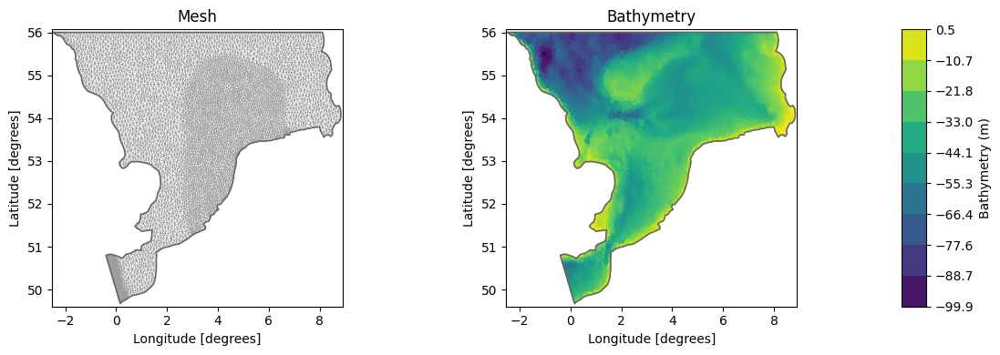

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

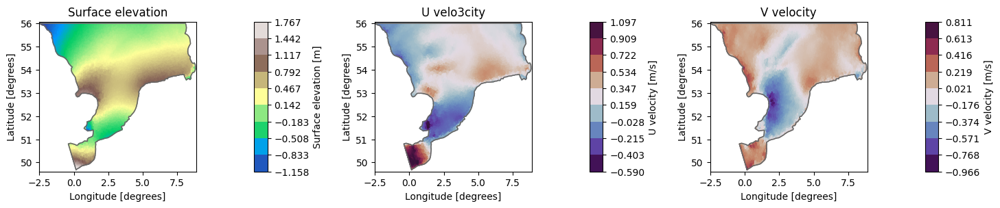

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


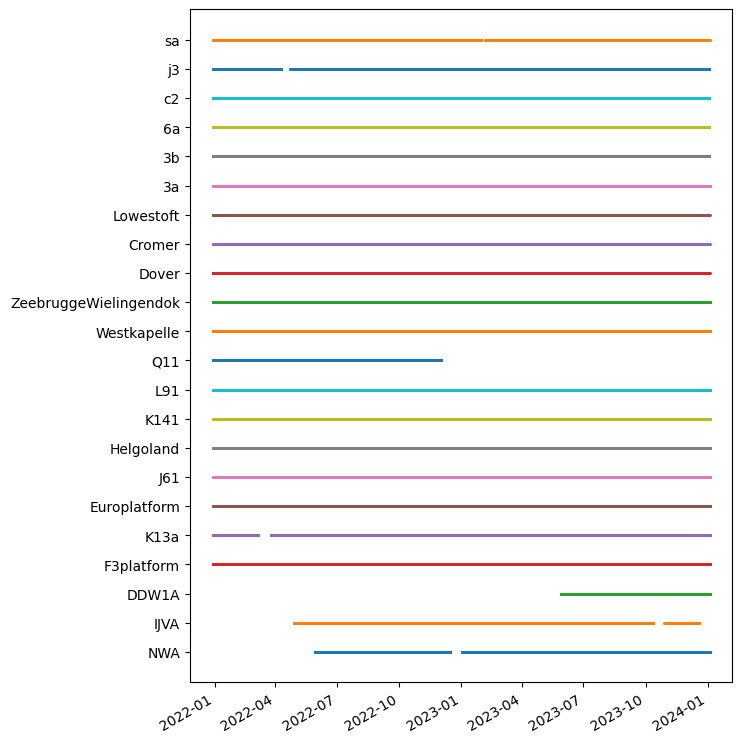

In [6]:
# sensor coverage

wllist = get_wl_point_obs()
altlist = get_altimetry_obs()

alllist = wllist + altlist
ms.plotting.temporal_coverage(alllist)
plt.show()

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(alllist)):
    stations.append(alllist[i])
    if ds.time.isin(alllist[i].time).all():
        availables.append(alllist[i])
    else:
        intermittent.append(alllist[i])

print(f"Total stations: {len(stations)}")
print(f"Stations with full temporal coverage: {len(availables)}")
print(f"Intermittent stations: {len(intermittent)}")

Total stations: 22
Stations with full temporal coverage: 5
Intermittent stations: 17


In [8]:
# Extract water level measurements

measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)

In [9]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 22])


In [10]:
ERRORS = []

## Idea 0: Only Available Sensors

In [11]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in availables]
measurements_av = measurements[:, av_indices]

time_steps, _ = measurements_av.shape

# Count NaNs for intermittent stations
intermittent_indices = [stations.index(s) for s in intermittent]
nan_counts_intermittent = np.isnan(measurements[:, intermittent_indices].numpy()).sum(axis=0)

# Build a clean coverage table and sort by coverage percentage
rows = []
for i, s in enumerate(intermittent):
    ok_count = int(time_steps - nan_counts_intermittent[i])
    nan_count = int(nan_counts_intermittent[i])
    coverage = 100 * ok_count / time_steps
    rows.append({
        "station": s.name,
        "ok": ok_count,
        "nans": nan_count,
        "coverage_%": round(coverage, 1),
    })
coverage_df = pd.DataFrame(rows).sort_values("coverage_%", ascending=False).reset_index(drop=True)

print(f"Intermittent stations ({len(intermittent)}):")
display(coverage_df.style.format({"ok": "{:,}", "nans": "{:,}", "coverage_%": "{:.1f}"}))

Intermittent stations (17):


,station,ok,nans,coverage_%
0,F3platform,"35,021",18,99.9
1,K141,"34,972",67,99.8
2,Europlatform,"34,604",435,98.8
3,K13a,"33,888","1,151",96.7
4,IJVA,"26,743","8,296",76.3
5,NWA,"26,469","8,570",75.5
6,Dover,"17,024","18,015",48.6
7,Lowestoft,"16,988","18,051",48.5
8,Cromer,"16,719","18,320",47.7
9,Q11,"15,900","19,139",45.4


## Idea T.1.A: Median imputer

In [12]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="median"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 22]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 22]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 22]) -> torch.Size([3504, 120])

Input shape for the model: 22
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [24:17<00:00,  7.29s/it, Train Loss=0.0038, Val Loss=0.0040, Patience=0, Best Val Loss=0.0040, LR=0.00e+00] 

Training completed with best validation loss: 0.0040


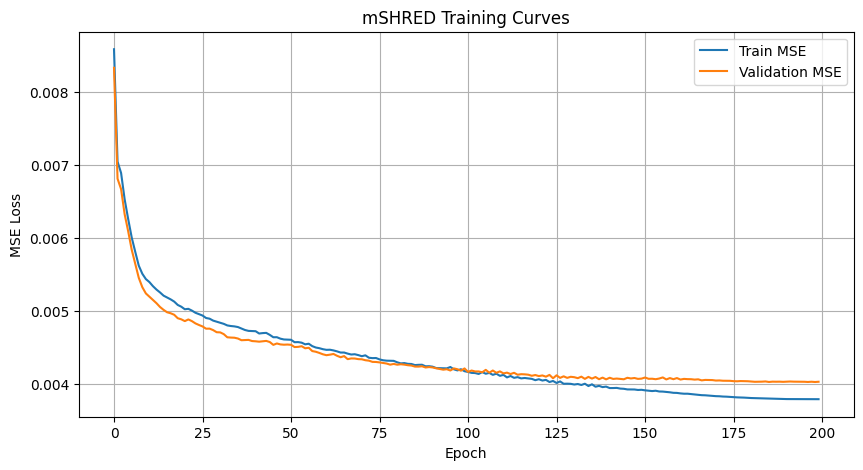

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222


In [13]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.A) median imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_A_median_imputation.png


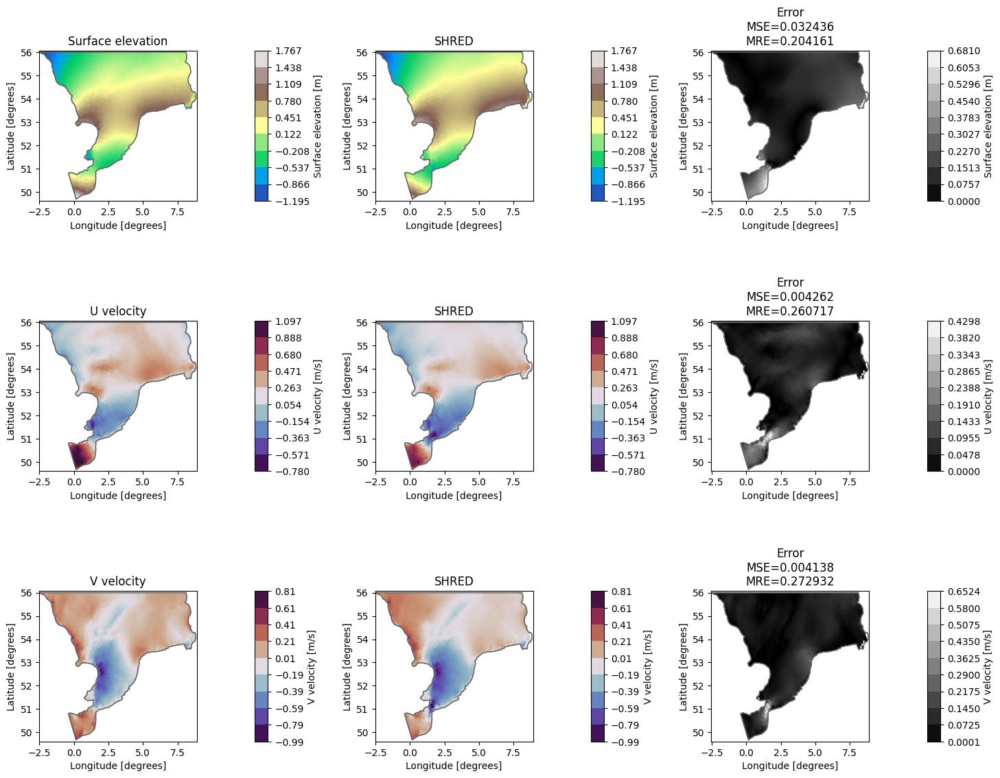

In [14]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_A_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.A: Median imputer 


Starting training...


Training: 100%|██████████| 200/200 [08:17<00:00,  2.49s/it, Train Loss=0.0037, Val Loss=0.0040, Patience=10, Best Val Loss=0.0040, LR=0.00e+00]


Training completed with best validation loss: 0.0040


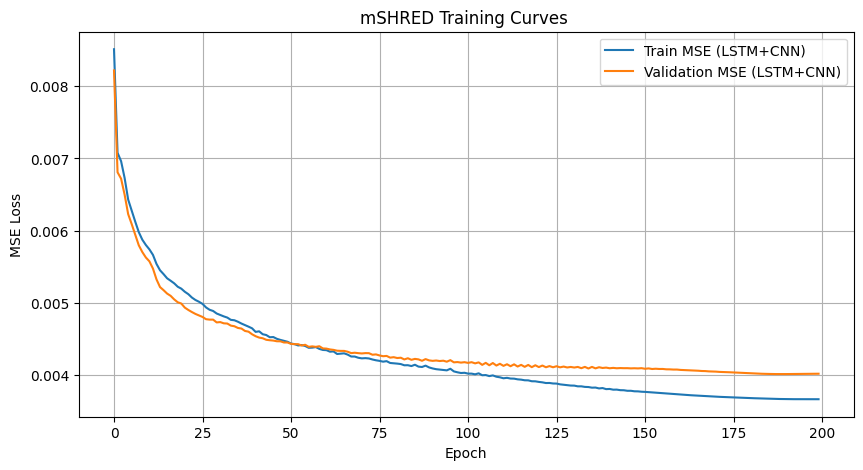

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168


In [15]:

# mSHRED TRAINING (Idea S.1.A) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.A) median imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_A_median_imputation.png


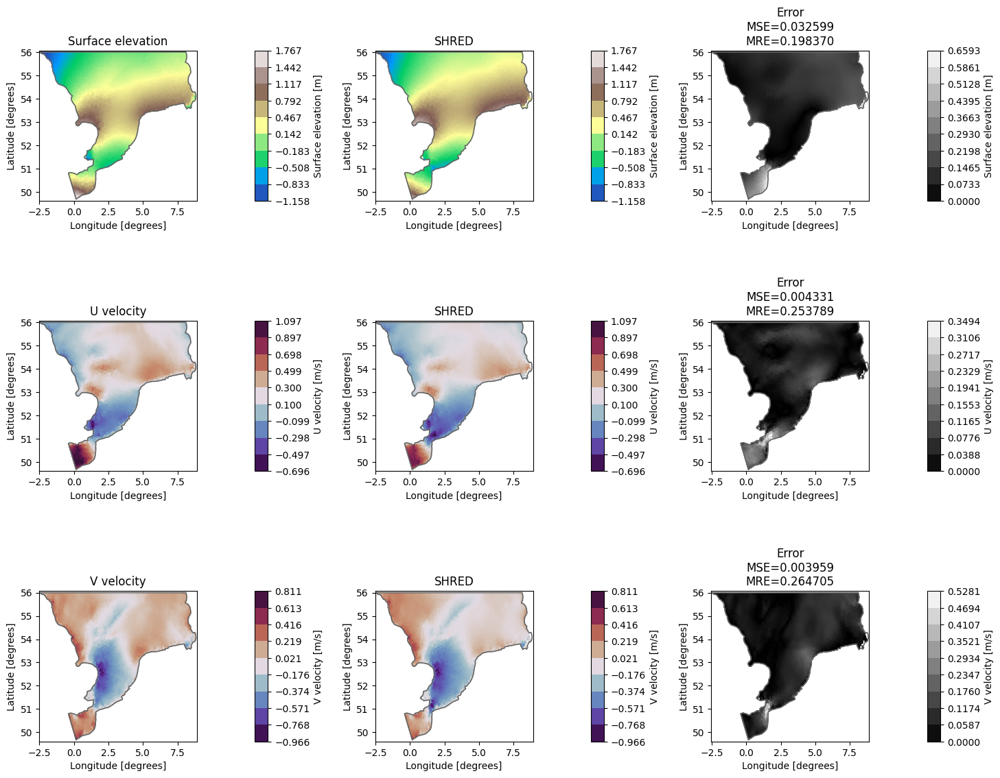

In [16]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_A_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea T.1.B: Mean imputer

In [17]:
# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="mean"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 22]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 22]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 22]) -> torch.Size([3504, 120])

Input shape for the model: 22
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [24:08<00:00,  7.24s/it, Train Loss=0.0038, Val Loss=0.0040, Patience=0, Best Val Loss=0.0040, LR=0.00e+00]

Training completed with best validation loss: 0.0040


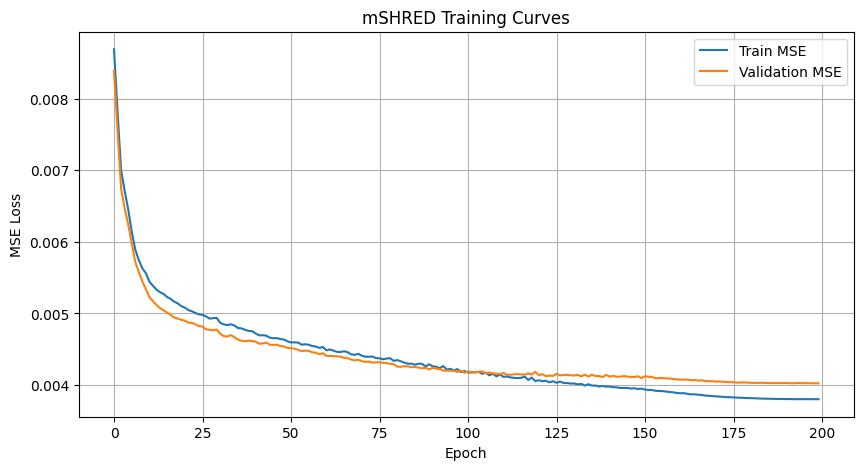

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718


In [18]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.B) mean imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_B_mean_imputation.png


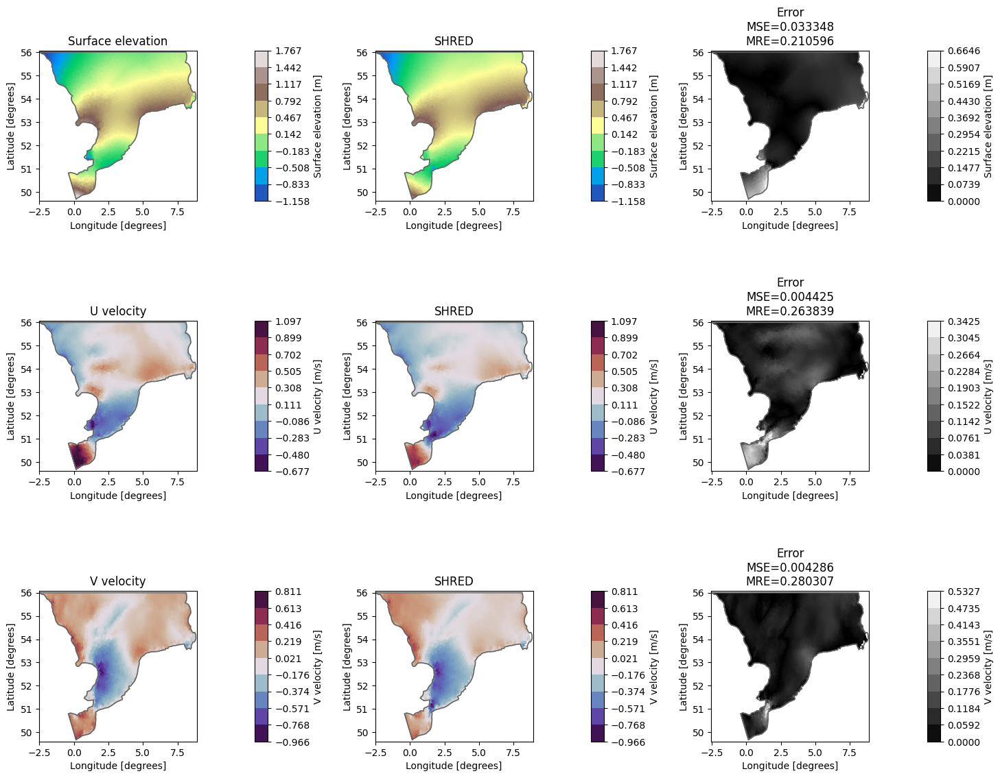

In [19]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_B_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.B: Mean imputer

Starting training...


Training: 100%|██████████| 200/200 [09:27<00:00,  2.84s/it, Train Loss=0.0037, Val Loss=0.0040, Patience=8, Best Val Loss=0.0040, LR=0.00e+00]

Training completed with best validation loss: 0.0040


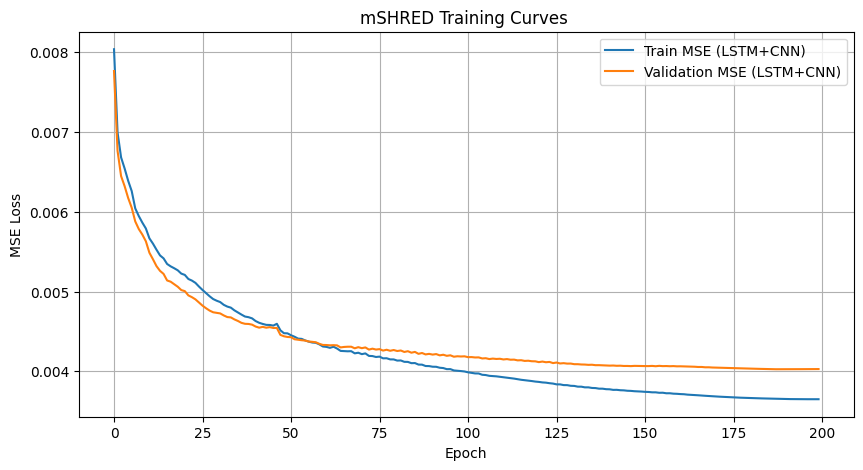

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941


In [20]:

# mSHRED TRAINING (Idea S.1.B) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.B) mean imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_B_mean_imputation.png


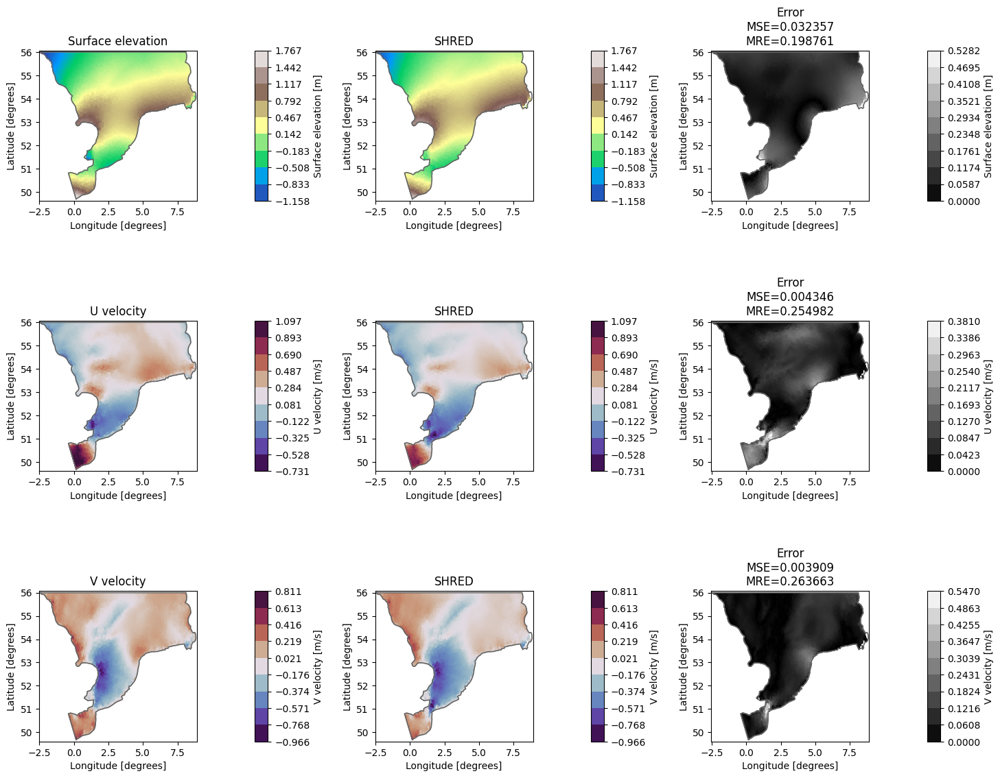

In [21]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_B_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea T.1.C: Last value imputer

In [22]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="last_value"
 )
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 22]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 22]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 22]) -> torch.Size([3504, 120])

Input shape for the model: 22
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [28:00<00:00,  8.40s/it, Train Loss=0.0038, Val Loss=0.0040, Patience=9, Best Val Loss=0.0040, LR=0.00e+00]

Training completed with best validation loss: 0.0040


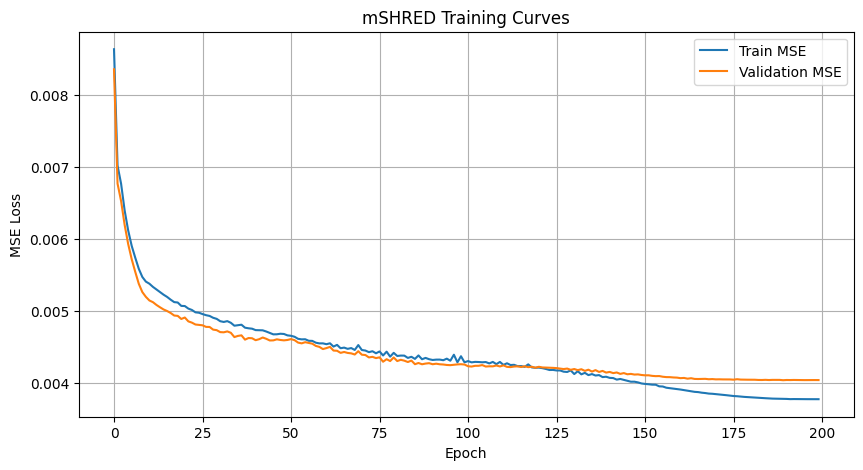

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032


In [23]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.C) last value imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_C_last_value_imputation.png


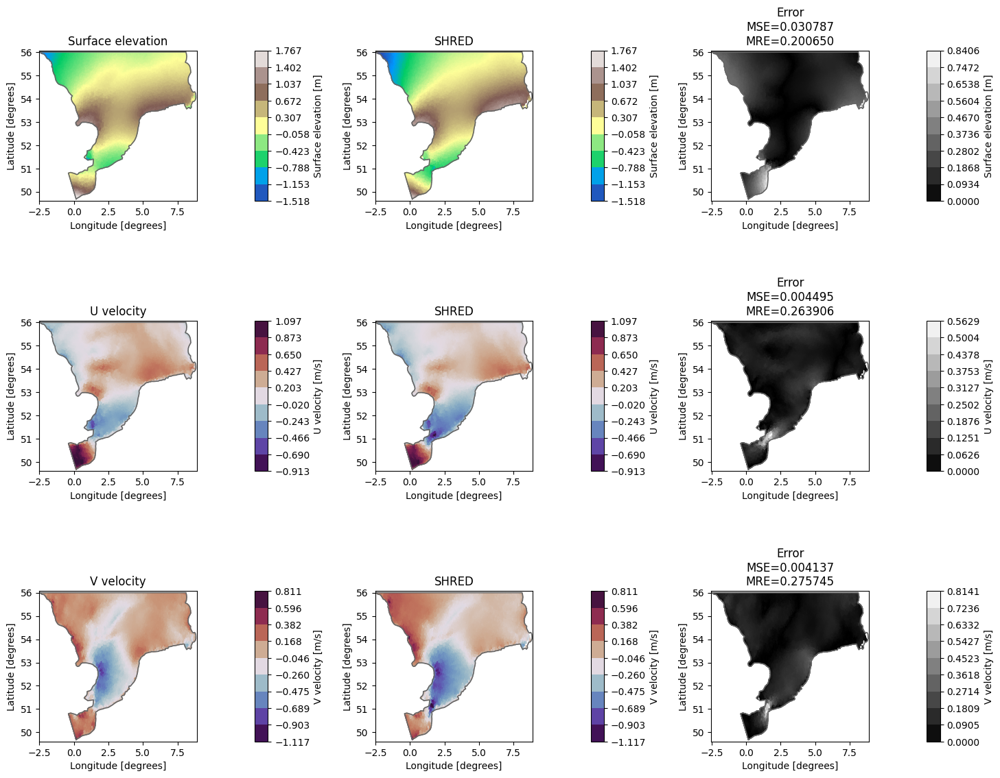

In [24]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_C_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.C: Last value imputer

Starting training...


Training: 100%|██████████| 200/200 [09:34<00:00,  2.87s/it, Train Loss=0.0037, Val Loss=0.0040, Patience=0, Best Val Loss=0.0040, LR=0.00e+00]

Training completed with best validation loss: 0.0040


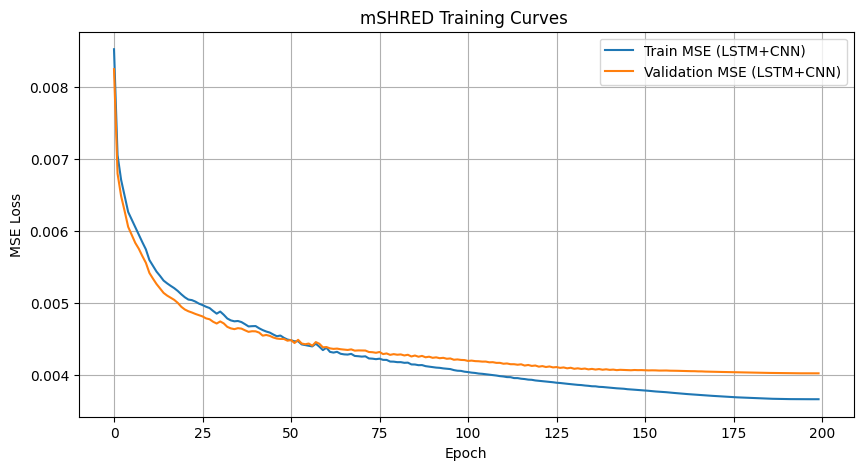

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707


In [25]:

# mSHRED TRAINING (Idea S.1.C) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.C) last value imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_C_last_value_imputation.png


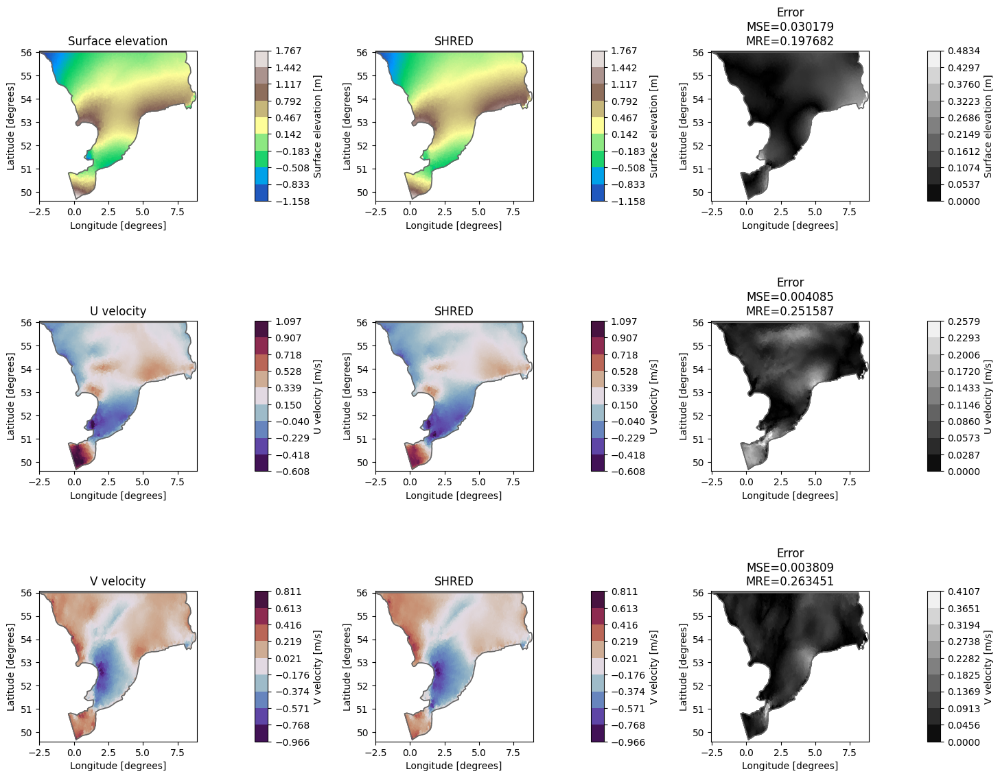

In [26]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_C_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea 2.A: GRUD

In [27]:

# Data manager
lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose = True, masking_type="grud")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 323400 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 4, 24, 22]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 4, 24, 22]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 4, 24, 22]) -> torch.Size([3504, 120])

Input shape for the model: 22
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [34:20<00:00, 10.30s/it, Train Loss=0.0039, Val Loss=0.0047, Patience=3, Best Val Loss=0.0047, LR=0.00e+00] 

Training completed with best validation loss: 0.0047


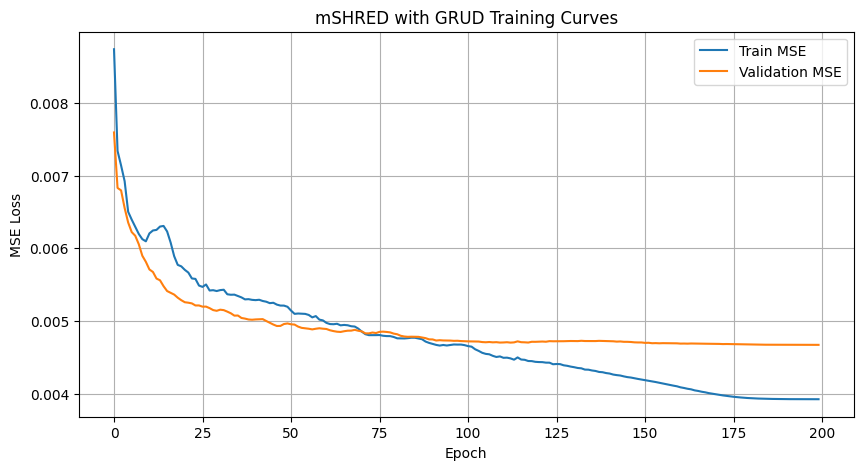

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003926,0.004673,0.010504,0.126288,0.136285,0.202451


In [28]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): GRUD + CNN",
    "type" : "(2.A) GRUD masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_A_GRUD_masking.png


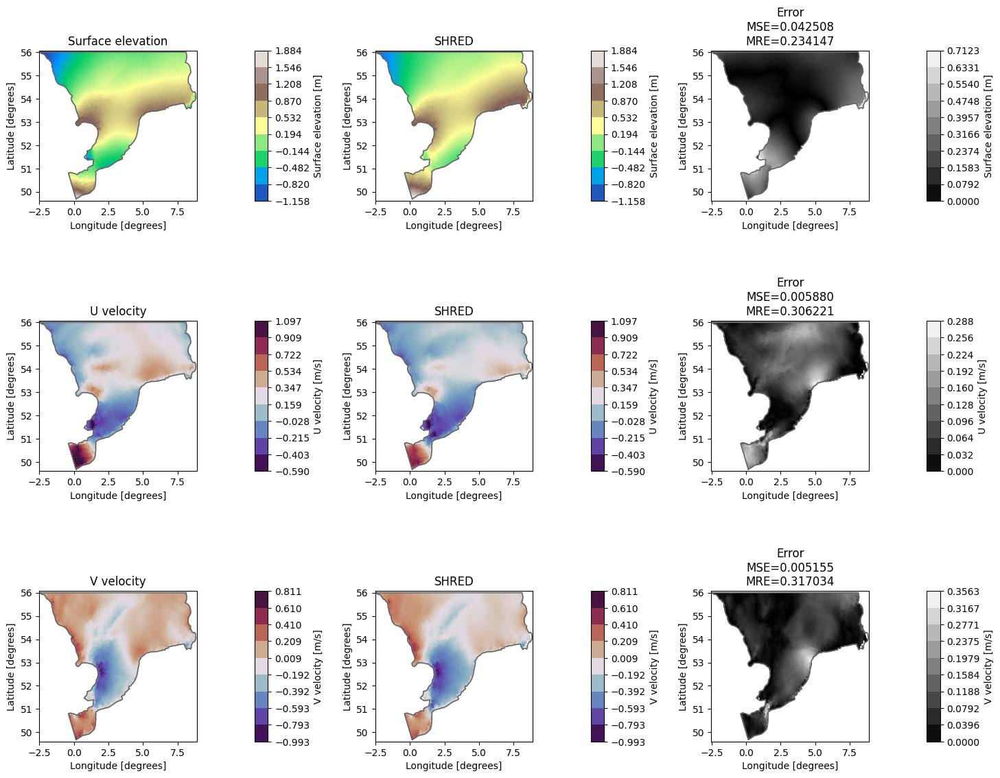

In [29]:

# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_A_GRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred


## Idea 2.B: Attn AGRUD


Starting training...


Training: 100%|██████████| 200/200 [1:02:24<00:00, 18.72s/it, Train Loss=0.0042, Val Loss=0.0050, Patience=2, Best Val Loss=0.0050, LR=0.00e+00]

Training completed with best validation loss: 0.0050


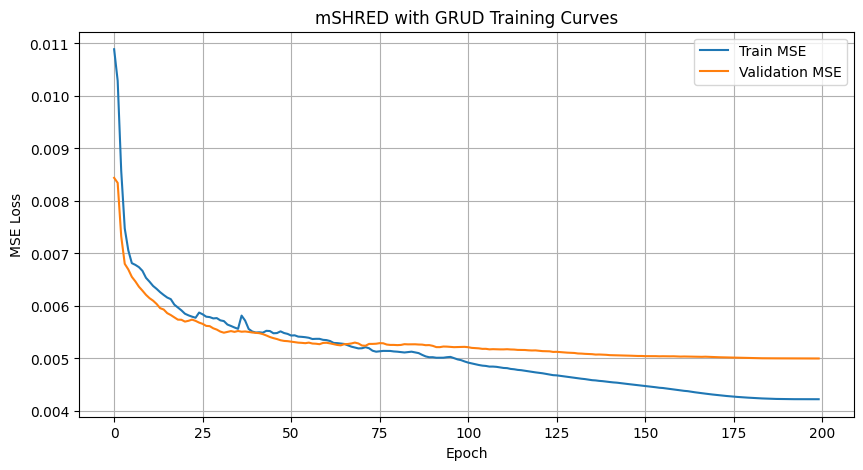

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003926,0.004673,0.010504,0.126288,0.136285,0.202451
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004224,0.005000,0.011547,0.130690,0.141352,0.212230


In [30]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): attnGRUD + CNN",
    "type" : "(2.B) GRUD masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_B_attnGRUD_masking.png


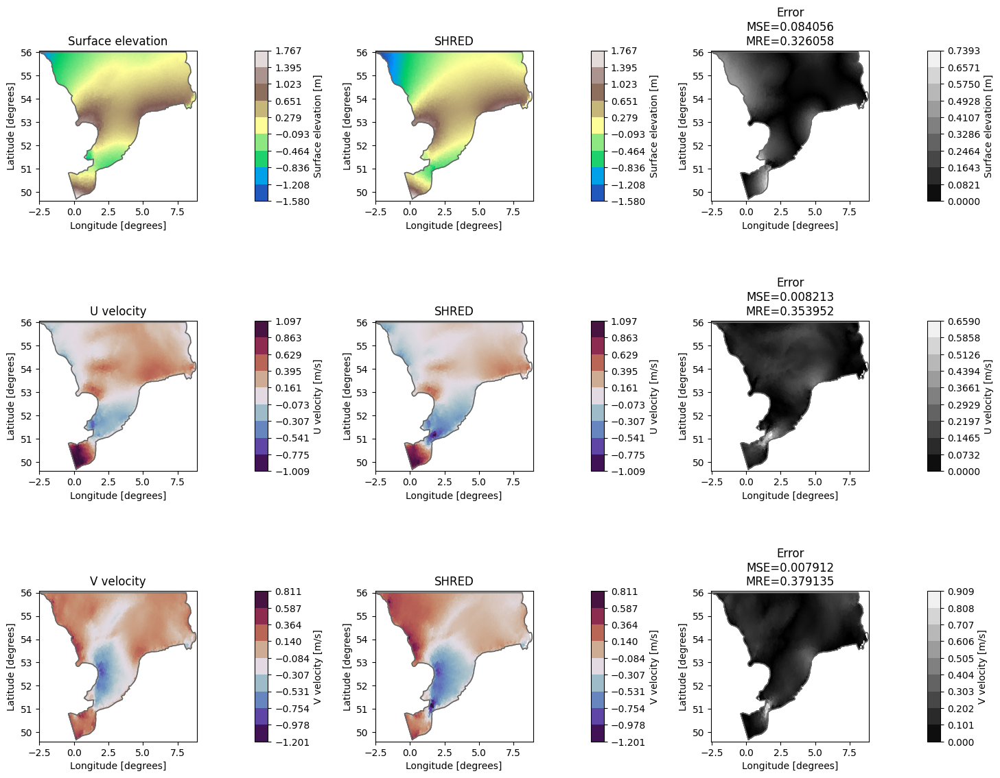

In [31]:

# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_B_attnGRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, manager


## Masking

In [32]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 12, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, masking_type="mask_data")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 323400 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 323400

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 22]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 22]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 22]) -> torch.Size([3504, 120])

Input shape for the model: 22
Output shape for the model: 120


## Idea 3.0: TSHRED

Starting training...


Training: 100%|██████████| 200/200 [31:14<00:00,  9.37s/it, Train Loss=0.0033, Val Loss=0.0041, Patience=8, Best Val Loss=0.0041, LR=0.00e+00] 

Training completed with best validation loss: 0.0041


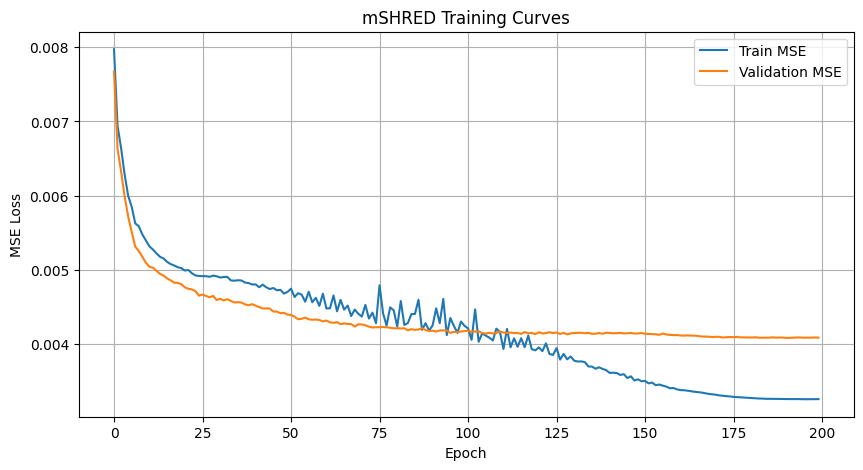

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003926,0.004673,0.010504,0.126288,0.136285,0.202451
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004224,0.005000,0.011547,0.130690,0.141352,0.212230
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.003253,0.004082,0.009887,0.115642,0.124887,0.196685


In [33]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset,masking_type= "mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.0) TSHRED",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_0_tshred.png


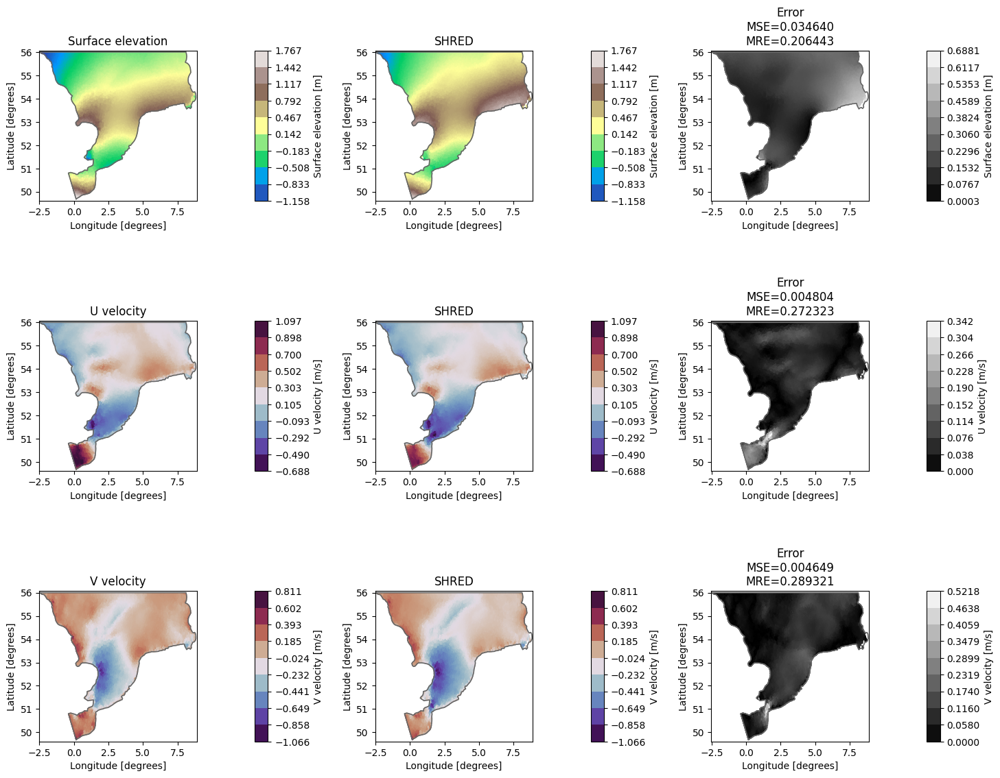

In [34]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_0_tshred")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.A: Mask double channels

Starting training...


Training: 100%|██████████| 200/200 [31:36<00:00,  9.48s/it, Train Loss=0.0033, Val Loss=0.0041, Patience=6, Best Val Loss=0.0041, LR=0.00e+00] 

Training completed with best validation loss: 0.0041


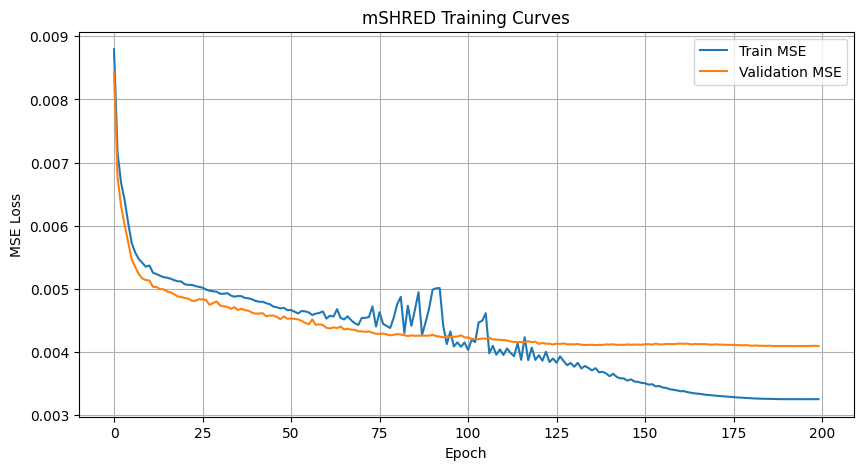

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003926,0.004673,0.010504,0.126288,0.136285,0.202451
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004224,0.005000,0.011547,0.130690,0.141352,0.212230
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.003253,0.004082,0.009887,0.115642,0.124887,0.196685
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003253,0.004094,0.010076,0.115315,0.125589,0.198125


In [35]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset,masking_type= "mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.A) Mask double channels",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_A_mask_double_channels.png


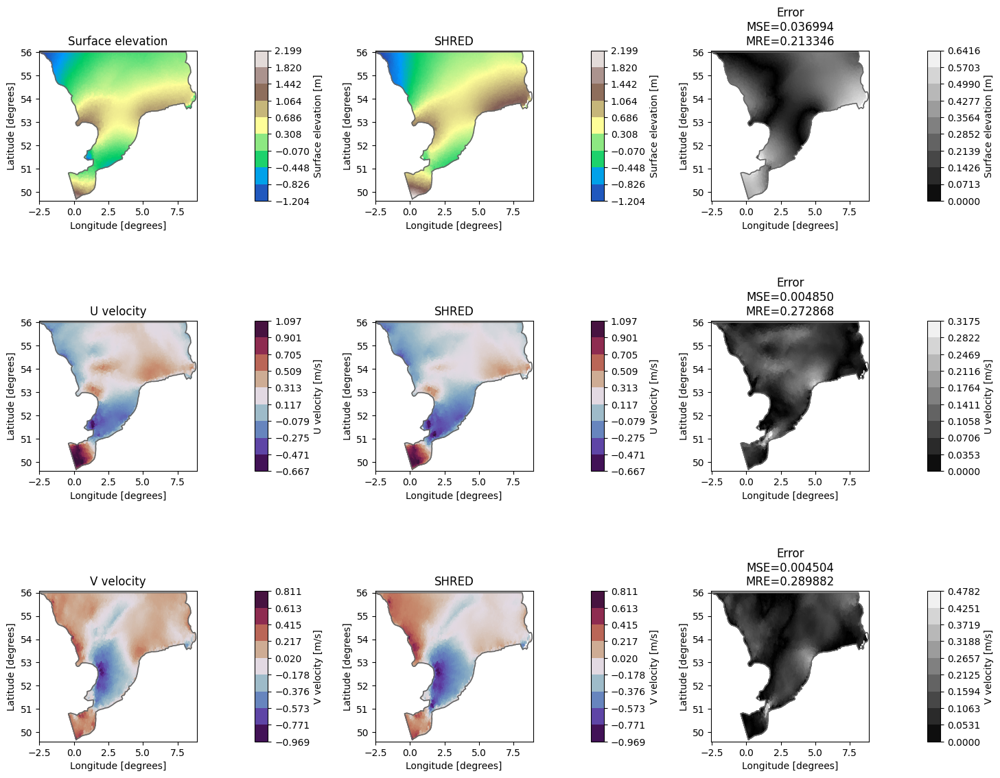

In [36]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_A_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.B: Mask in the hidden space

Starting training...


Training: 100%|██████████| 200/200 [32:56<00:00,  9.88s/it, Train Loss=0.0032, Val Loss=0.0041, Patience=6, Best Val Loss=0.0041, LR=0.00e+00] 


Training completed with best validation loss: 0.0041


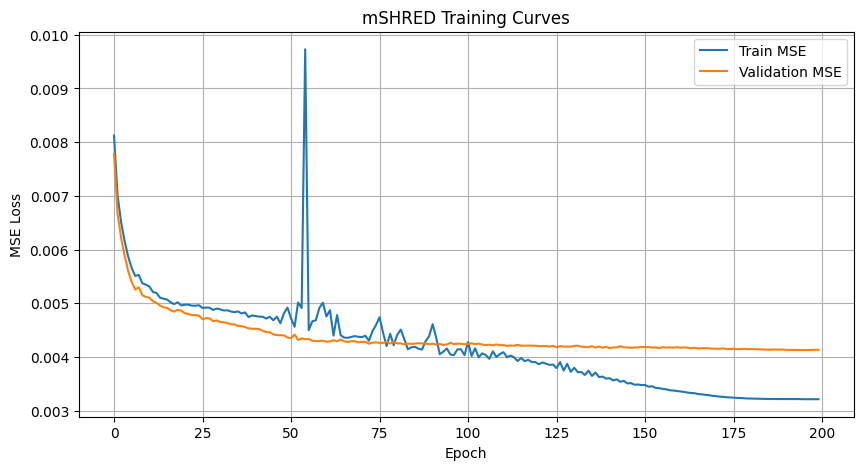

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003926,0.004673,0.010504,0.126288,0.136285,0.202451
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004224,0.005000,0.011547,0.130690,0.141352,0.212230
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.003253,0.004082,0.009887,0.115642,0.124887,0.196685
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003253,0.004094,0.010076,0.115315,0.125589,0.198125


In [37]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.B) Mask the hidden state",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_B_mask_hidden_state.png


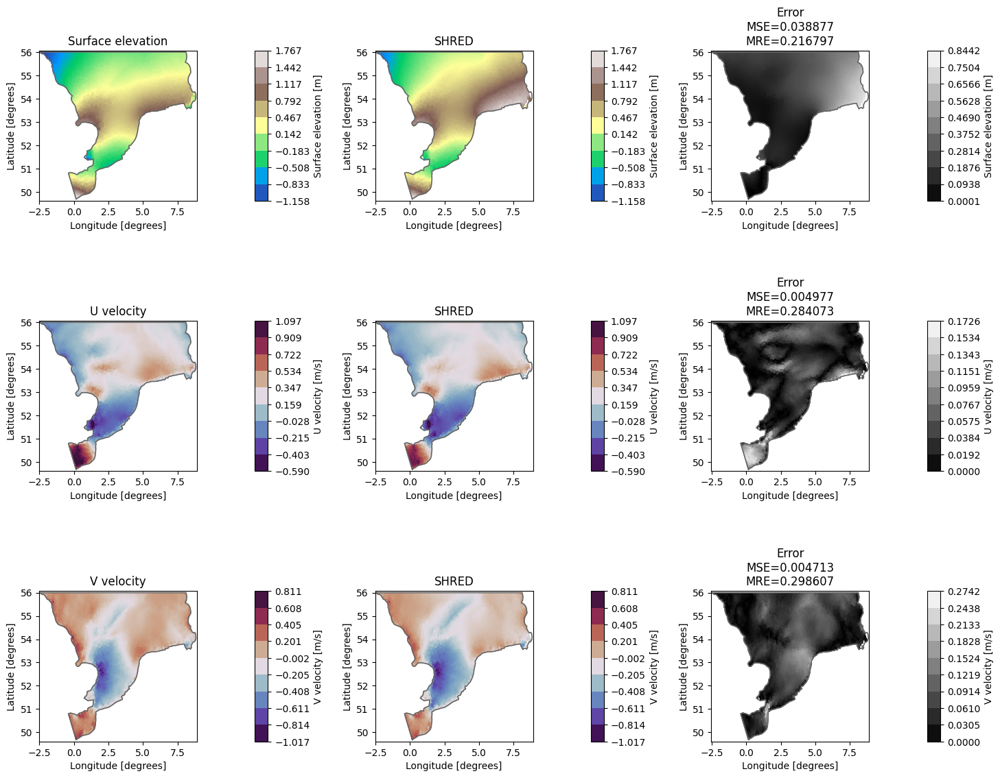

In [38]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_B_mask_hidden_state")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.C: Mask in the attention block

Starting training...


Training: 100%|██████████| 200/200 [33:39<00:00, 10.10s/it, Train Loss=0.0032, Val Loss=0.0041, Patience=3, Best Val Loss=0.0041, LR=0.00e+00] 

Training completed with best validation loss: 0.0041


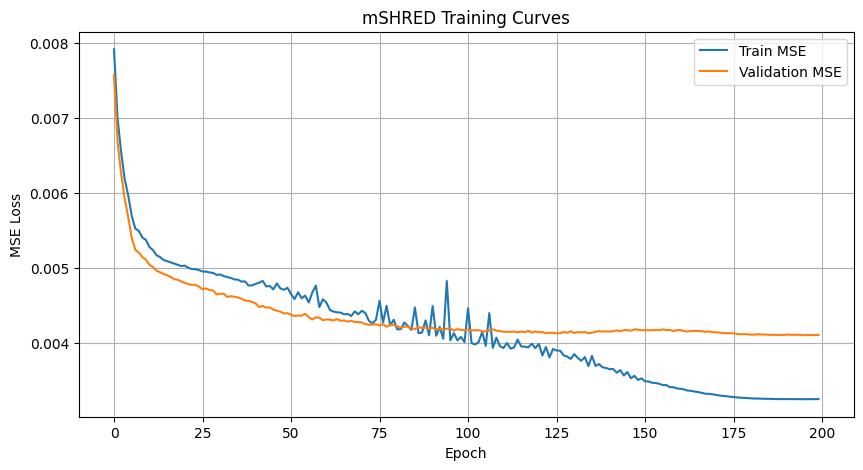

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003926,0.004673,0.010504,0.126288,0.136285,0.202451
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004224,0.005000,0.011547,0.130690,0.141352,0.212230
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.003253,0.004082,0.009887,0.115642,0.124887,0.196685
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003253,0.004094,0.010076,0.115315,0.125589,0.198125


In [39]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.C) Mask in the attention block",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_C_mask_attention_block.png


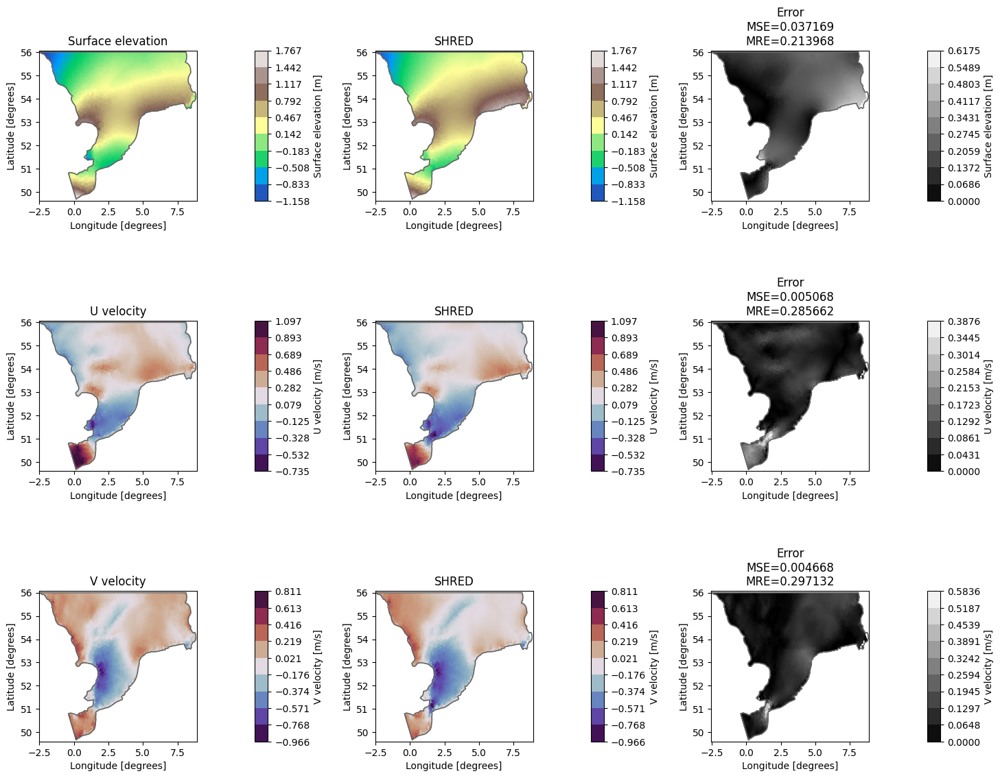

In [40]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_C_mask_attention_block")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.D: Attention mask + double channels

Starting training...


Training: 100%|██████████| 200/200 [33:27<00:00, 10.04s/it, Train Loss=0.0032, Val Loss=0.0041, Patience=1, Best Val Loss=0.0040, LR=0.00e+00] 

Training completed with best validation loss: 0.0040


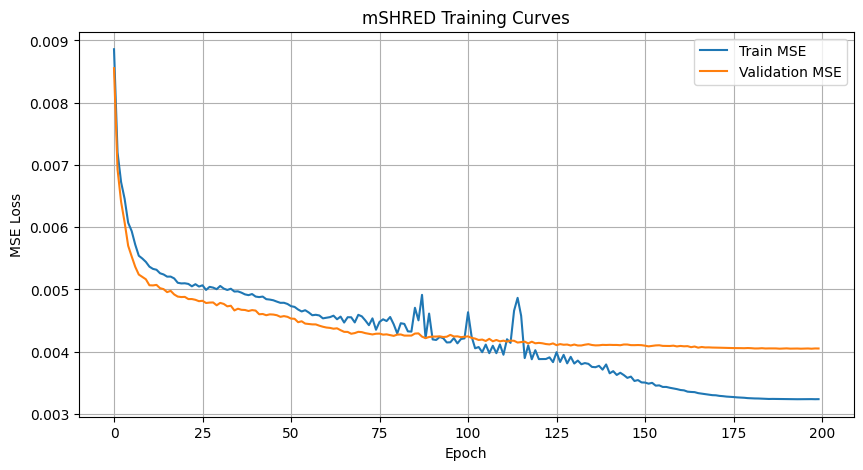

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003926,0.004673,0.010504,0.126288,0.136285,0.202451
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004224,0.005000,0.011547,0.130690,0.141352,0.212230
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.003253,0.004082,0.009887,0.115642,0.124887,0.196685
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003253,0.004094,0.010076,0.115315,0.125589,0.198125


In [41]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.D) Double masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_double_masking.png


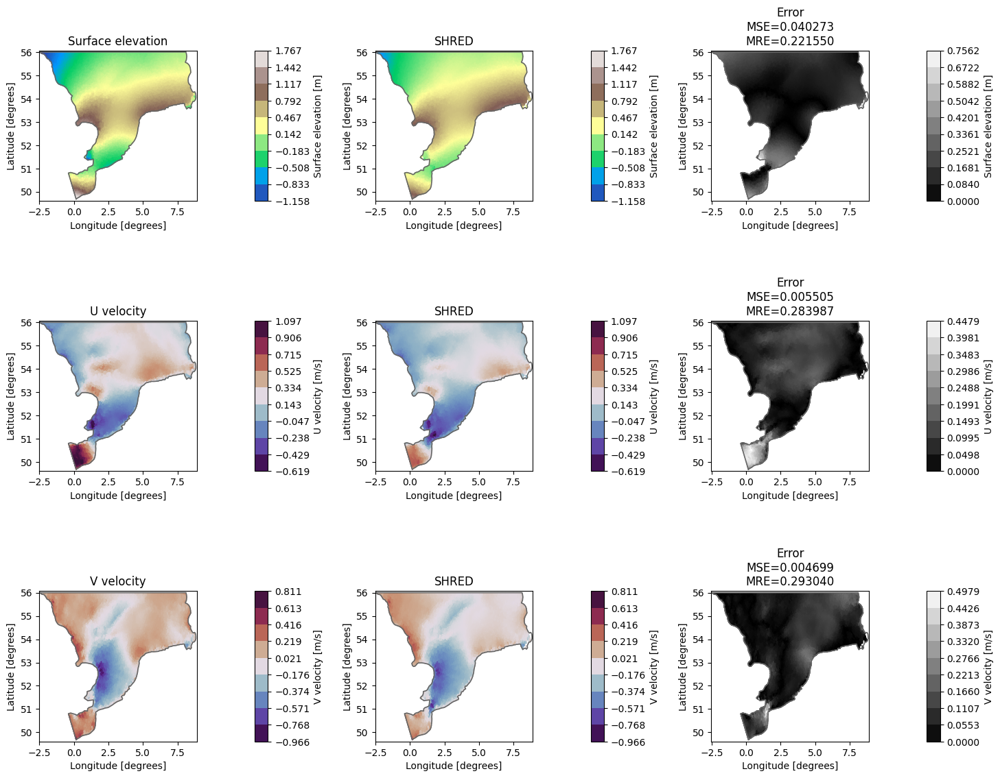

In [42]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_double_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.E: learn the mask in the softmax


Starting training...


Training: 100%|██████████| 200/200 [41:48<00:00, 12.54s/it, Train Loss=0.0031, Val Loss=0.0041, Patience=13, Best Val Loss=0.0041, LR=0.00e+00]

Training completed with best validation loss: 0.0041


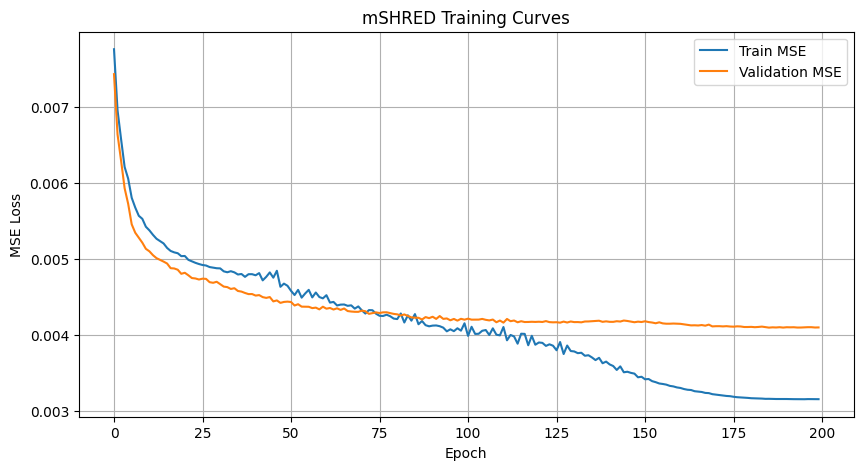

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003926,0.004673,0.010504,0.126288,0.136285,0.202451
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004224,0.005000,0.011547,0.130690,0.141352,0.212230
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.003253,0.004082,0.009887,0.115642,0.124887,0.196685
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003253,0.004094,0.010076,0.115315,0.125589,0.198125


In [43]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.E) Transformer Learned mask",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_learn_mask_softmax.png


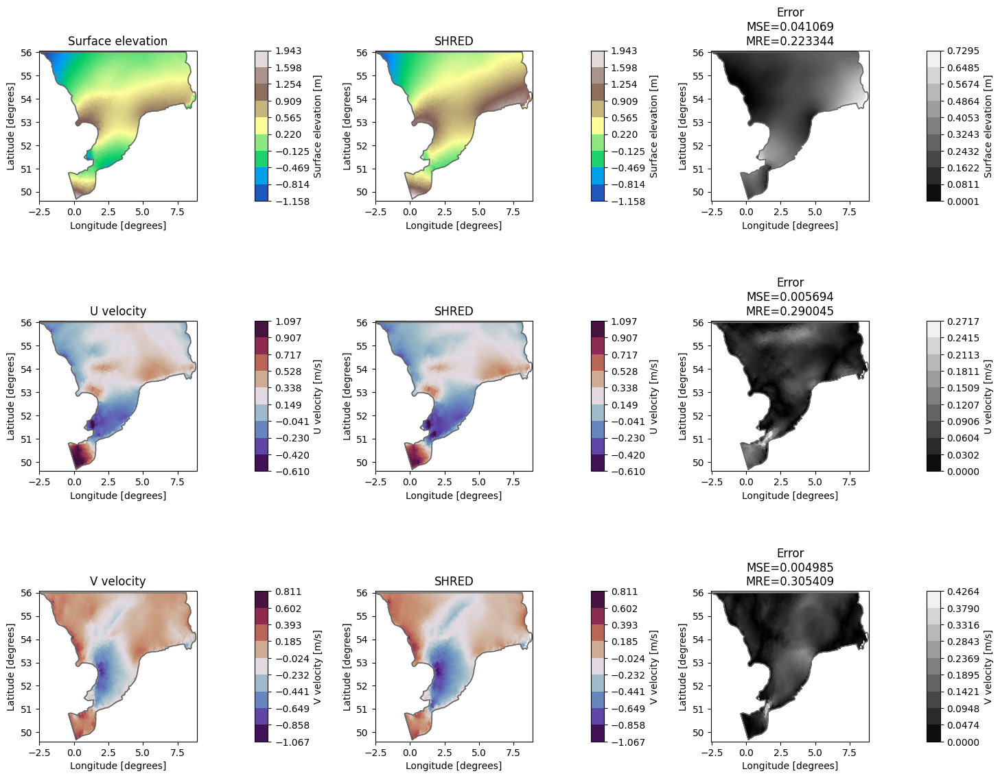

In [44]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_learn_mask_softmax")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.F: Learned mask + double channels


Starting training...


Training: 100%|██████████| 200/200 [40:24<00:00, 12.12s/it, Train Loss=0.0032, Val Loss=0.0041, Patience=3, Best Val Loss=0.0041, LR=0.00e+00] 

Training completed with best validation loss: 0.0041


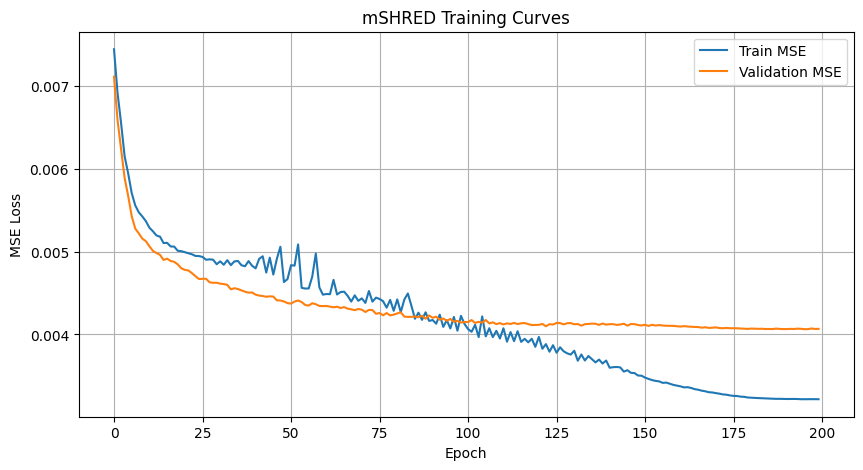

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003926,0.004673,0.010504,0.126288,0.136285,0.202451
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004224,0.005000,0.011547,0.130690,0.141352,0.212230
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.003253,0.004082,0.009887,0.115642,0.124887,0.196685
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003253,0.004094,0.010076,0.115315,0.125589,0.198125


In [45]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.F) Transformer Learned mask + double channels",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_F_learn_mask_double_channels.png


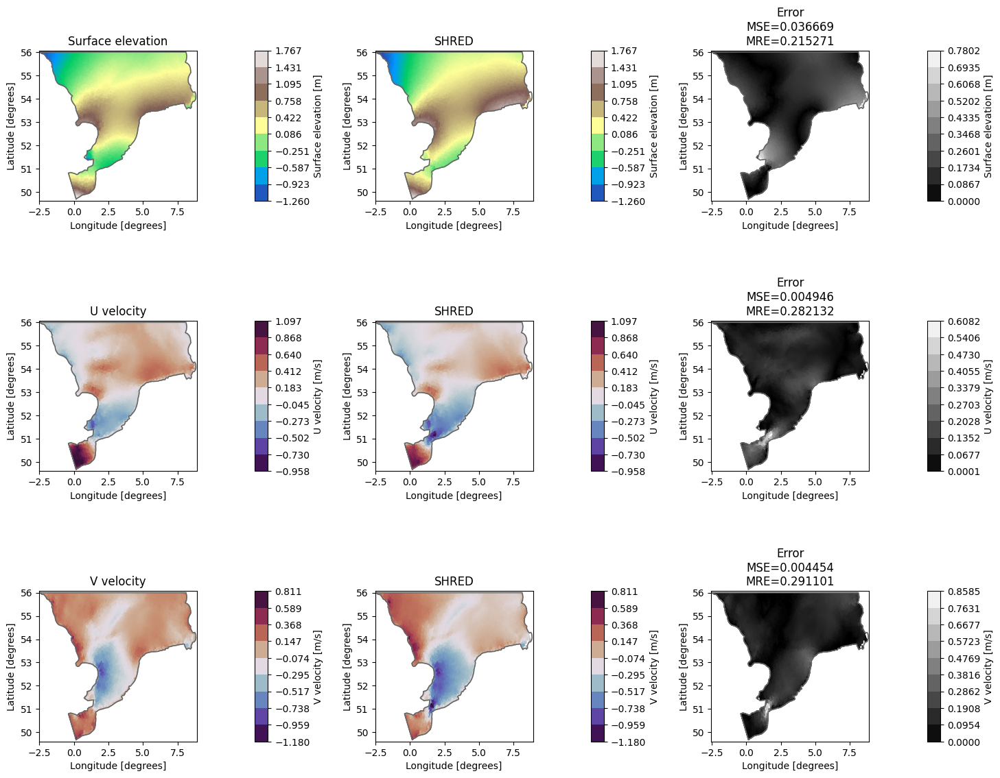

In [46]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_F_learn_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Results

In [47]:
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003926,0.004673,0.010504,0.126288,0.136285,0.202451
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004224,0.005000,0.011547,0.130690,0.141352,0.212230
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.003253,0.004082,0.009887,0.115642,0.124887,0.196685
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003253,0.004094,0.010076,0.115315,0.125589,0.198125


In [50]:
# order dataframe by test-mse
dataframe_errors = dataframe_errors.sort_values(by="test-mse")
display(dataframe_errors)

# order dataframe by test-mre
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
10,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.003218,0.004135,0.009858,0.114967,0.125869,0.196499
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.003253,0.004082,0.009887,0.115642,0.124887,0.196685
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
14,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.003221,0.004068,0.009920,0.115135,0.125101,0.197176
11,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.003244,0.004101,0.009958,0.115415,0.125303,0.197491
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003770,0.004038,0.009716,0.123975,0.125160,0.195032
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003789,0.004024,0.009734,0.123991,0.125064,0.195222
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003661,0.004021,0.009767,0.122527,0.125082,0.195707
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003802,0.004027,0.009793,0.124392,0.125283,0.195718
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003670,0.004023,0.009894,0.122255,0.125072,0.196168
10,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.003218,0.004135,0.009858,0.114967,0.125869,0.196499
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.003253,0.004082,0.009887,0.115642,0.124887,0.196685
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003650,0.004028,0.009961,0.122161,0.125055,0.196941
14,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.003221,0.004068,0.009920,0.115135,0.125101,0.197176
12,(mSHRED): TR + MLP,(3.D) Double masking,0.003238,0.004048,0.010003,0.115264,0.124740,0.197303


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.A) median imputation for missing sensors</td>
      <td>0.003789</td>
      <td>0.004024</td>
      <td>0.009734</td>
      <td>0.123991</td>
      <td>0.125064</td>
      <td>0.195222</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.A) median imputation for missing sensors</td>
      <td>0.003670</td>
      <td>0.004023</td>
      <td>0.009894</td>
      <td>0.122255</td>
      <td>0.125072</td>
      <td>0.196168</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.B) mean imputation for missing sensors</td>
      <td>0.003802</td>
      <td>0.004027</td>
      <td>0.009793</td>
      <td>0.124392</td>
      <td>0.125283</td>
      <td>0.195718</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.B) mean imputation for missing sensors</td>
      <td>0.003650</td>
      <td>0.004028</td>
      <td>0.009961</td>
      <td>0.122161</td>
      <td>0.125055</td>
      <td>0.196941</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.C) last value imputation for missing sensors</td>
      <td>0.003770</td>
      <td>0.004038</td>
      <td>0.009716</td>
      <td>0.123975</td>
      <td>0.125160</td>
      <td>0.195032</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.C) last value imputation for missing sensors</td>
      <td>0.003661</td>
      <td>0.004021</td>
      <td>0.009767</td>
      <td>0.122527</td>
      <td>0.125082</td>
      <td>0.195707</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): GRUD + CNN</td>
      <td>(2.A) GRUD masking</td>
      <td>0.003926</td>
      <td>0.004673</td>
      <td>0.010504</td>
      <td>0.126288</td>
      <td>0.136285</td>
      <td>0.202451</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): attnGRUD + CNN</td>
      <td>(2.B) GRUD masking</td>
      <td>0.004224</td>
      <td>0.005000</td>
      <td>0.011547</td>
      <td>0.130690</td>
      <td>0.141352</td>
      <td>0.212230</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.0) TSHRED</td>
      <td>0.003253</td>
      <td>0.004082</td>
      <td>0.009887</td>
      <td>0.115642</td>
      <td>0.124887</td>
      <td>0.196685</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.A) Mask double channels</td>
      <td>0.003253</td>
      <td>0.004094</td>
      <td>0.010076</td>
      <td>0.115315</td>
      <td>0.125589</td>
      <td>0.198125</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.B) Mask the hidden state</td>
      <td>0.003218</td>
      <td>0.004135</td>
      <td>0.009858</td>
      <td>0.114967</td>
      <td>0.125869</td>
      <td>0.196499</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.C) Mask in the attention block</td>
      <td>0.003244</td>
      <td>0.004101</td>
      <td>0.009958</td>
      <td>0.115415</td>
      <td>0.125303</td>
      <td>0.197491</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.D) Double masking</td>
      <td>0.003238</td>
      <td>0.004048</td>
      <td>0.010003</td>
      <td>0.115264</td>
      <td>0.124740</td>
      <td>0.197303</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.E) Transformer Learned mask</td>
      <td>0.003148</td>
      <td>0.004095</td>
      <td>0.010179</td>
      <td>0.114063</td>
      <td>0.125382</td>
      <td>0.199382</td>
    </tr>
    <tr>
      <th>14</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.F) Transformer Learned mask + double channels</td>
      <td>0.003221</td>
      <td>0.004068</td>
      <td>0.009920</td>
      <td>0.115135</td>
      <td>0.125101</td>
      <td>0.197176</td>
    </tr>
  </tbody>
</table>
</div>

## 